In [17]:
!pip install tensorflow
from keras.datasets import reuters
!pip install keras
from keras.datasets import reuters

In [18]:
(train_data,train_labels),(test_data,test_labels)=reuters.load_data(num_words=10000)

In [19]:
import numpy as np
def vectorize_sequences(sequences,dimension=10000):
  results=np.zeros((len(sequences),dimension))
  for i,sequence in enumerate(sequences):
    results[i,sequence]=1
  return results

In [20]:
x_train= vectorize_sequences(train_data)
x_test= vectorize_sequences(test_data)

In [21]:
def to_one_hot(labels,dimension=46):
  results=np.zeros((len(labels),dimension))
  for i,label in enumerate(labels):
    results[i,label]=1
  return results
one_hot_train_labels=to_one_hot(train_labels)
one_hot_test_labels=to_one_hot(test_labels)

In [22]:
one_hot_train_labels=to_one_hot(train_labels)
one_hot_test_labels=to_one_hot(test_labels)

In [23]:
from keras import models
from keras import layers
model = models.Sequential()
model.add(layers.Dense(64,activation='relu',input_shape=(10000,)))
model.add(layers.Dense(64,activation='relu'))
model.add(layers.Dense(46,activation='softmax'))

In [24]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 64)                  │         640,064 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 46)                  │           2,990 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 647,214 (2.47 MB)

 Trainable params: 647,214 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(optimizer='rmsprop',loss='categorical_crossentropy',metrics=['acc'])

In [26]:
x_val = x_train[:1000]
partial_x_train =x_train[1000:]

In [27]:
y_val = one_hot_train_labels[:1000]
partial_y_train = one_hot_train_labels[1000:]

In [28]:
history = model.fit(partial_x_train,partial_y_train,epochs=10,batch_size=512,validation_data=(x_val,y_val))

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 173ms/step - acc: 0.4944 - loss: 2.6765 - val_acc: 0.6160 - val_loss: 1.7970
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - acc: 0.6828 - loss: 1.5076 - val_acc: 0.6920 - val_loss: 1.3888
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - acc: 0.7432 - loss: 1.1766 - val_acc: 0.7220 - val_loss: 1.2223
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - acc: 0.7909 - loss: 0.9626 - val_acc: 0.7380 - val_loss: 1.1473
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - acc: 0.8235 - loss: 0.8054 - val_acc: 0.7610 - val_loss: 1.0546
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - acc: 0.8553 - loss: 0.6707 - val_acc: 0.7980 - val_loss: 0.9616
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - acc: 0.8814 - loss: 0.5611 - val_acc: 0.8050 - val_loss: 0.9288
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - acc: 0.9002 - loss: 0.4702 - val_acc: 0.7980 - val_loss: 0.9192
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - acc: 0.914

In [29]:
history_dict = history.history
history_dict.keys()

dict_keys(['acc', 'loss', 'val_acc', 'val_loss'])

In [30]:
import matplotlib.pyplot as plt

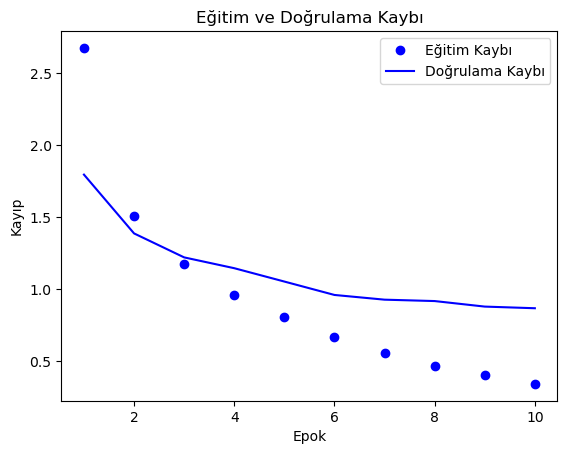

In [31]:
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1,len(loss)+1)
epochs
plt.plot(epochs,loss,'bo',label='Eğitim Kaybı')
plt.plot(epochs,val_loss,'b',label='Doğrulama Kaybı')
plt.title('Eğitim ve Doğrulama Kaybı')
plt.xlabel('Epok')
plt.ylabel('Kayıp')
plt.legend()
plt.show()

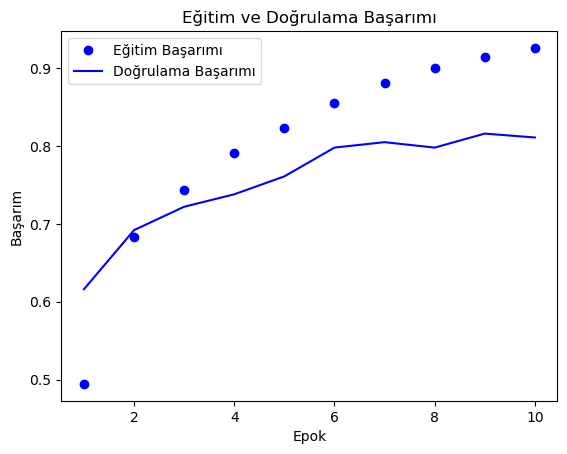

In [33]:
plt.clf()
acc=history.history['acc']
val_acc=history.history['val_acc']
plt.plot(epochs,acc,'bo',label='Eğitim Başarımı')
plt.plot(epochs,val_acc,'b',label='Doğrulama Başarımı')
plt.title('Eğitim ve Doğrulama Başarımı')
plt.xlabel('Epok')
plt.ylabel('Başarım')
plt.legend()
plt.show()